# Capital One Data Analysis — Executive Report

**Prepared by:** Venkata Lakshmi 
**Date:** 2026-07-20  
**Data scope:** Sales, Buyers, Vendors (11 supplier files)

---

This report answers five business questions using the cleaned transaction dataset. Each section states the finding, shows the supporting chart, and closes with a recommendation. All figures were generated from the same pipeline that powers the analysis notebooks.

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent
sys.path.insert(0, str(project_root / "src"))

from IPython.display import display, Image
FIGURES = project_root / "outputs" / "figures"


---
## Q1 — Staffing: Is 24/7 coverage justified?

**Finding:** Order volume is heavily concentrated in daytime hours.
The overnight window (12 am–6 am Central) represents a small fraction of total orders.

**Recommendation:** Replace flat 24/7 staffing with a tiered model:
- Full operational coverage during peak hours
- Reduced on-call overnight
- Track fulfillment SLA and cancellation rate as guardrail KPIs before reducing headcount

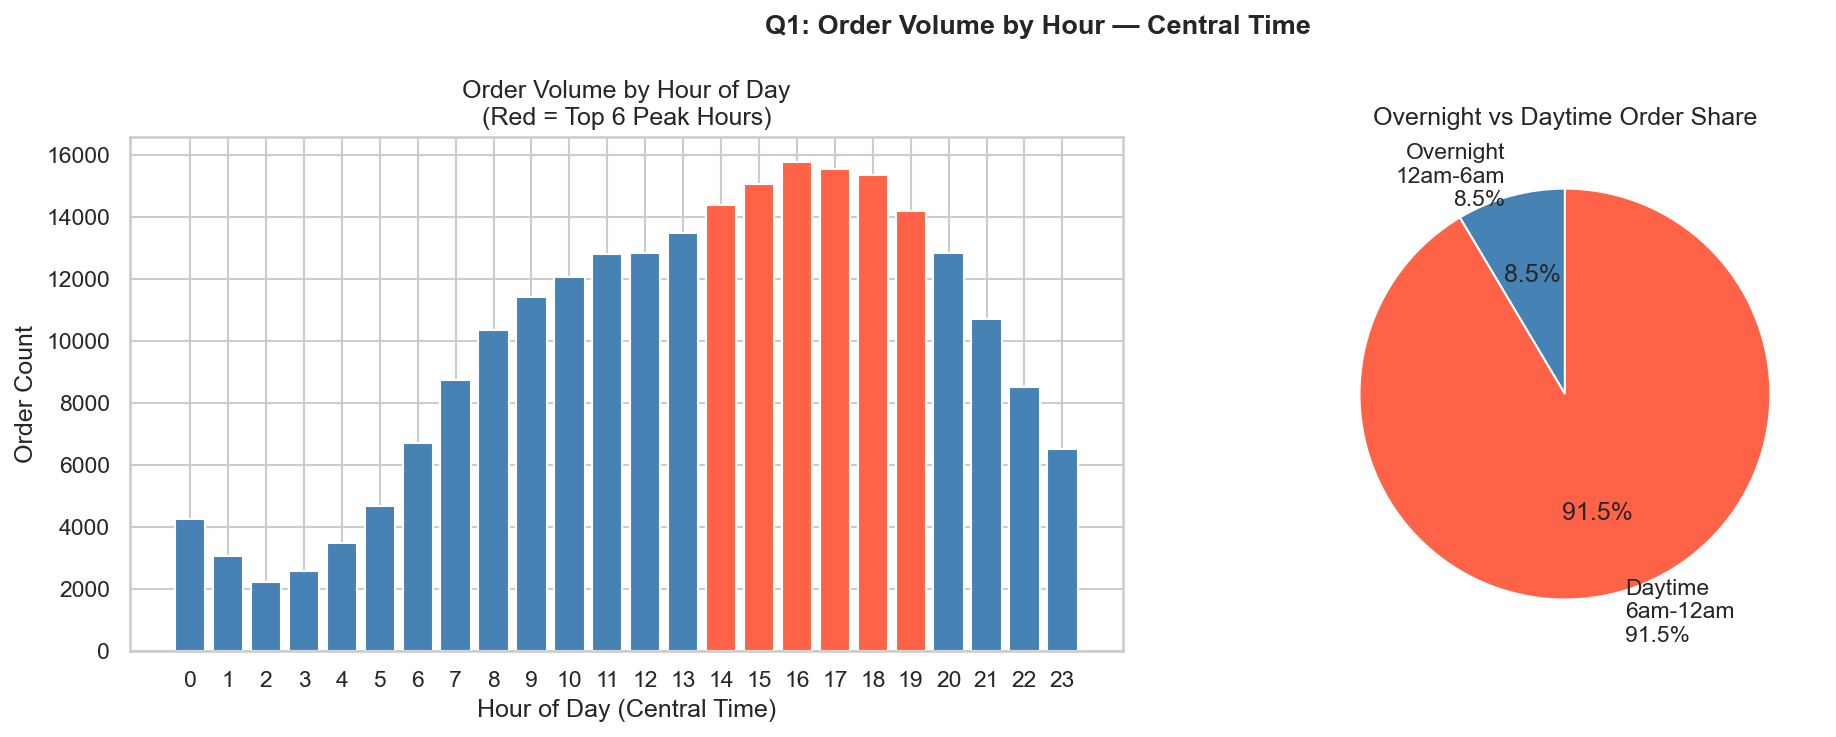

In [2]:
display(Image(FIGURES / "q1_hourly_volume.png"))


---
## Q2 — Profitability: Which segments drive profit, and is it stable?

**Finding:** VIP customers consistently generate the highest average profit per order across all quarters.
Occasional buyers show the lowest and most volatile returns.

**Note on Dormant:** Dormant buyers have zero orders in the dataset — not low activity,
literally none. This affects ~23,700 of ~47,500 total buyers (~50%).
See Q5 for activation implications.

**Recommendation:** - Invest in VIP and Frequent retention — they are the most stable profit drivers
- Monitor any segment showing quarter-over-quarter decline as an early warning signal

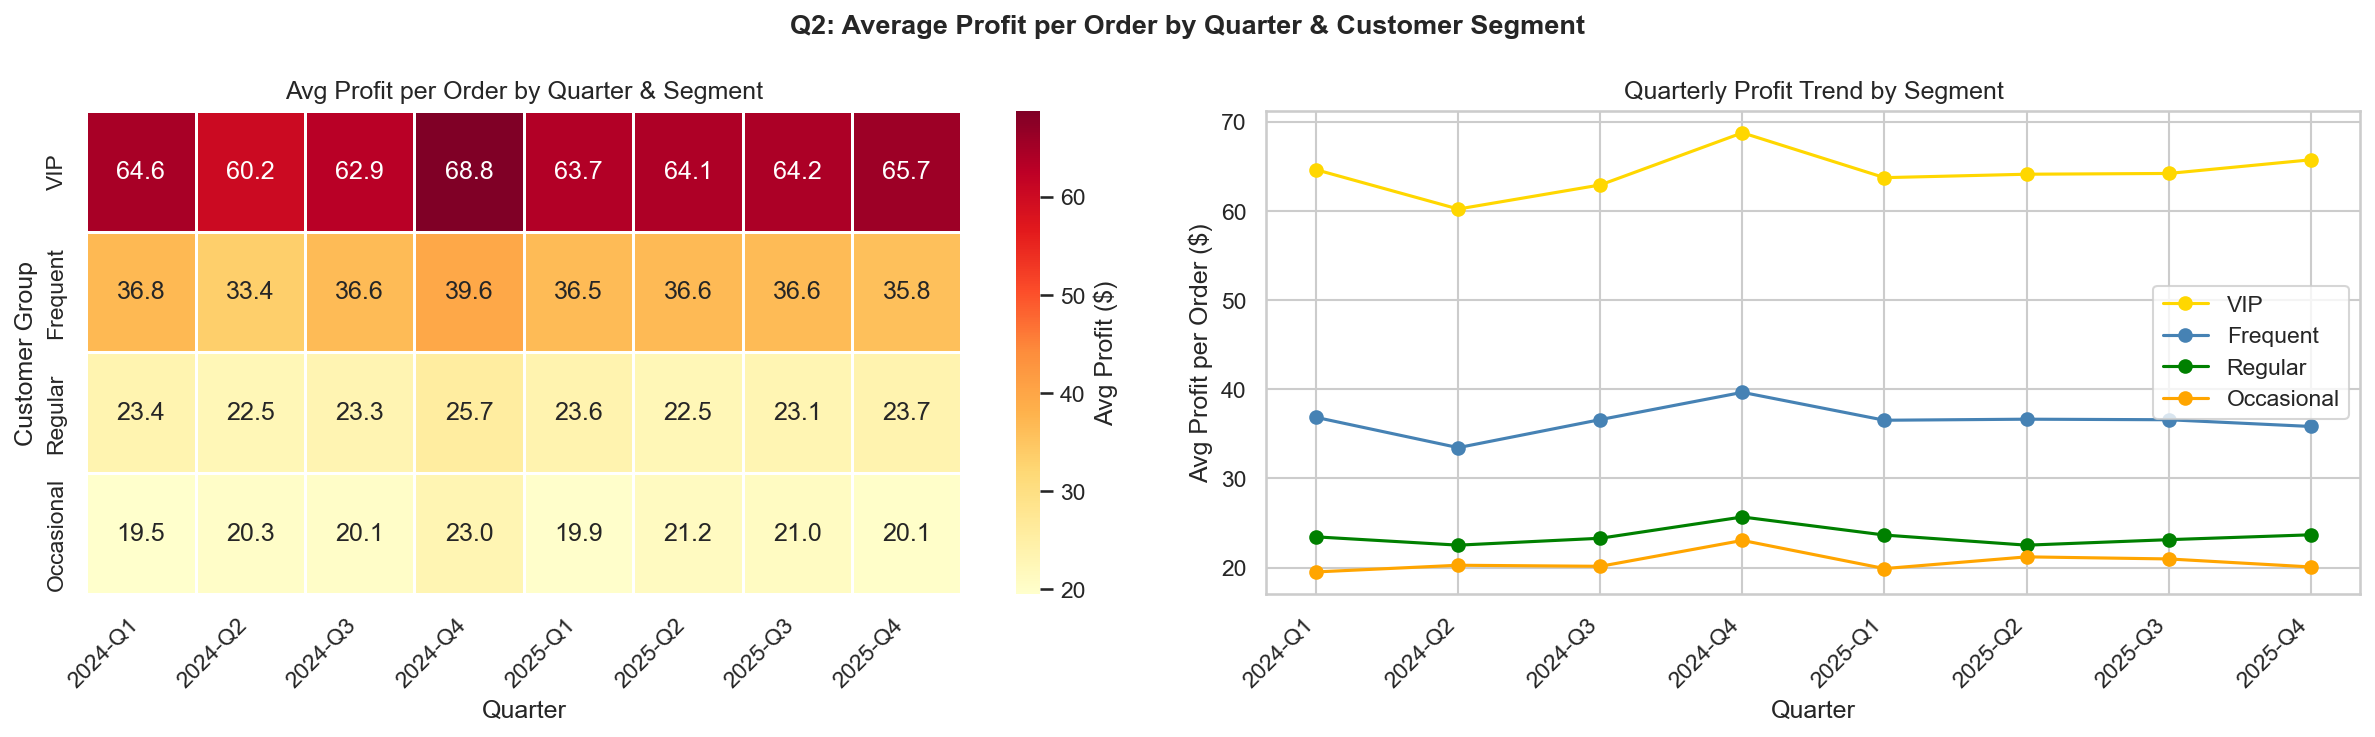

In [3]:
display(Image(FIGURES / "q2_profit_by_quarter_segment.png"))


---
## Q3 — Referral Program: What is it costing, and is it working?

**Finding:** Referred and non-referred buyers show nearly identical average revenue per buyer
and orders per buyer. The referral program is acquiring customers who behave the same
as organic customers — the discount appears to provide no behavioral lift.

> **Assumption — confirm with business.**
> Referral cost estimated at 10% off the first order.
> Referral cost is estimated using the placeholder rate from config (confirm actual terms
with the business before citing any cost figure operationally).

**Recommendation:** - Confirm the actual referral discount terms with the business before citing any cost figure
- Run a 90-day cohort retention analysis on referred vs non-referred buyers
- Consider restructuring the incentive: smaller first-order discount with a credit on the
  second order to create a measurable retention signal

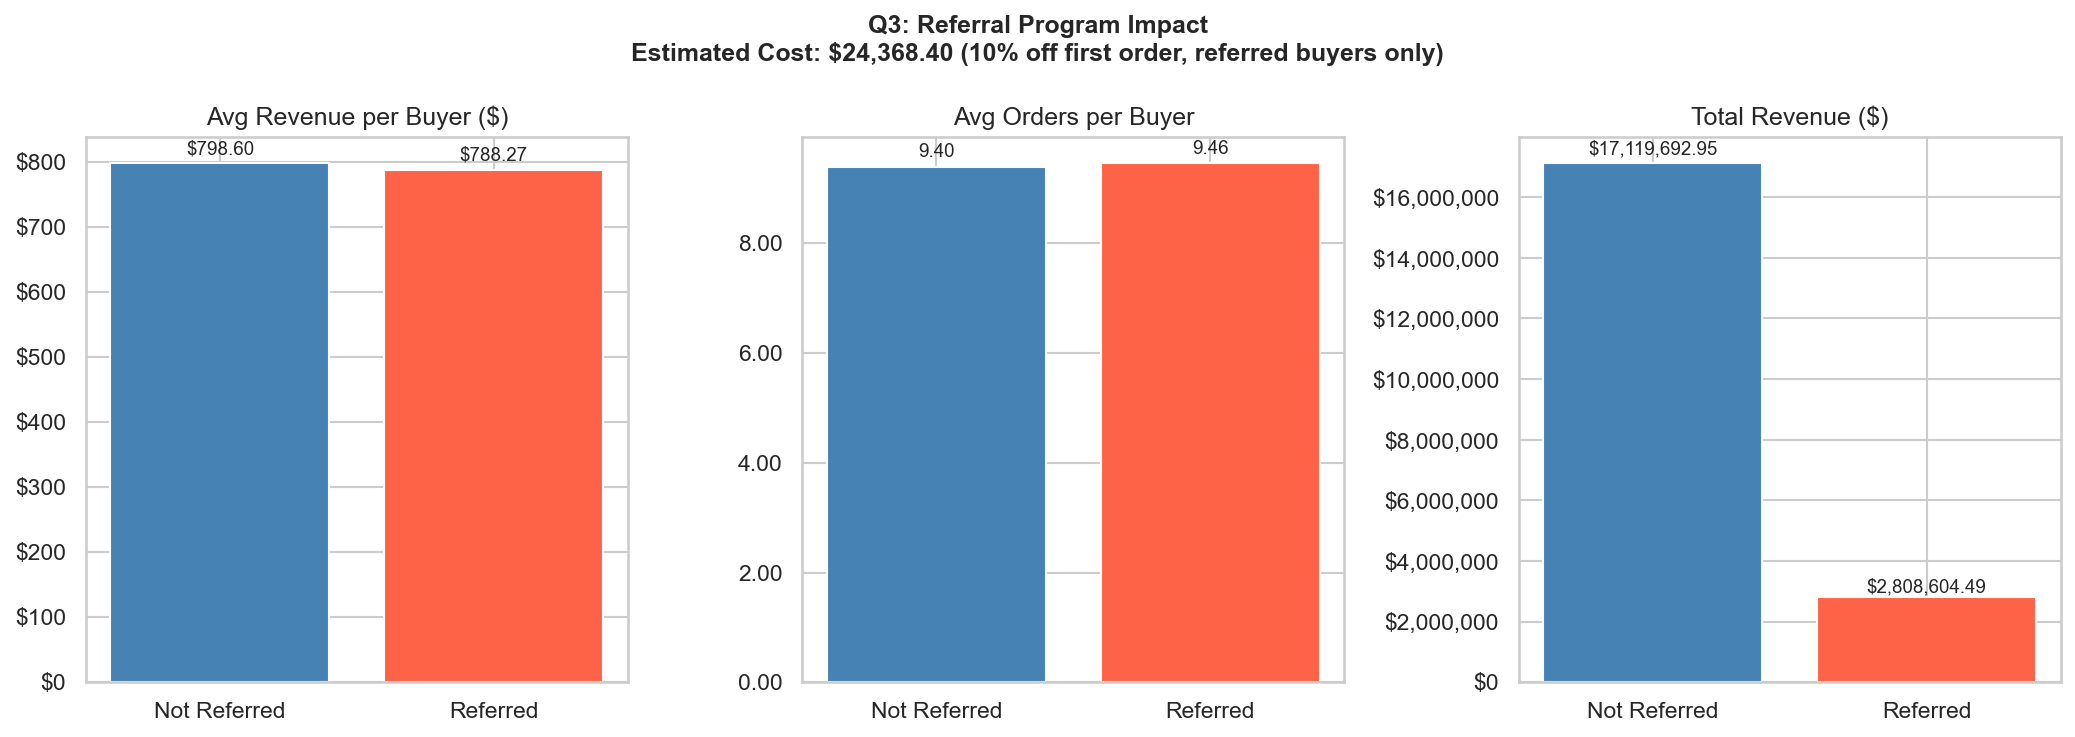

In [4]:
display(Image(FIGURES / "q3_referral_program.png"))


---
## Q4 — Black Friday: Volume spike or genuine revenue event?

**Finding:** Black Friday drives a concentrated spike in order volume and revenue, but represents
a small share of annual totals. Revenue figures reflect actual recorded values —
no promotional discount rate is available in the source data.

**Recommendation:** - Position Black Friday as a customer **acquisition** event, not a revenue event
- Target Occasional buyers with BF promotions and follow up in Q1 to move them to Frequent
- Monitor year-over-year BF revenue share to detect cannibalization of regular purchases

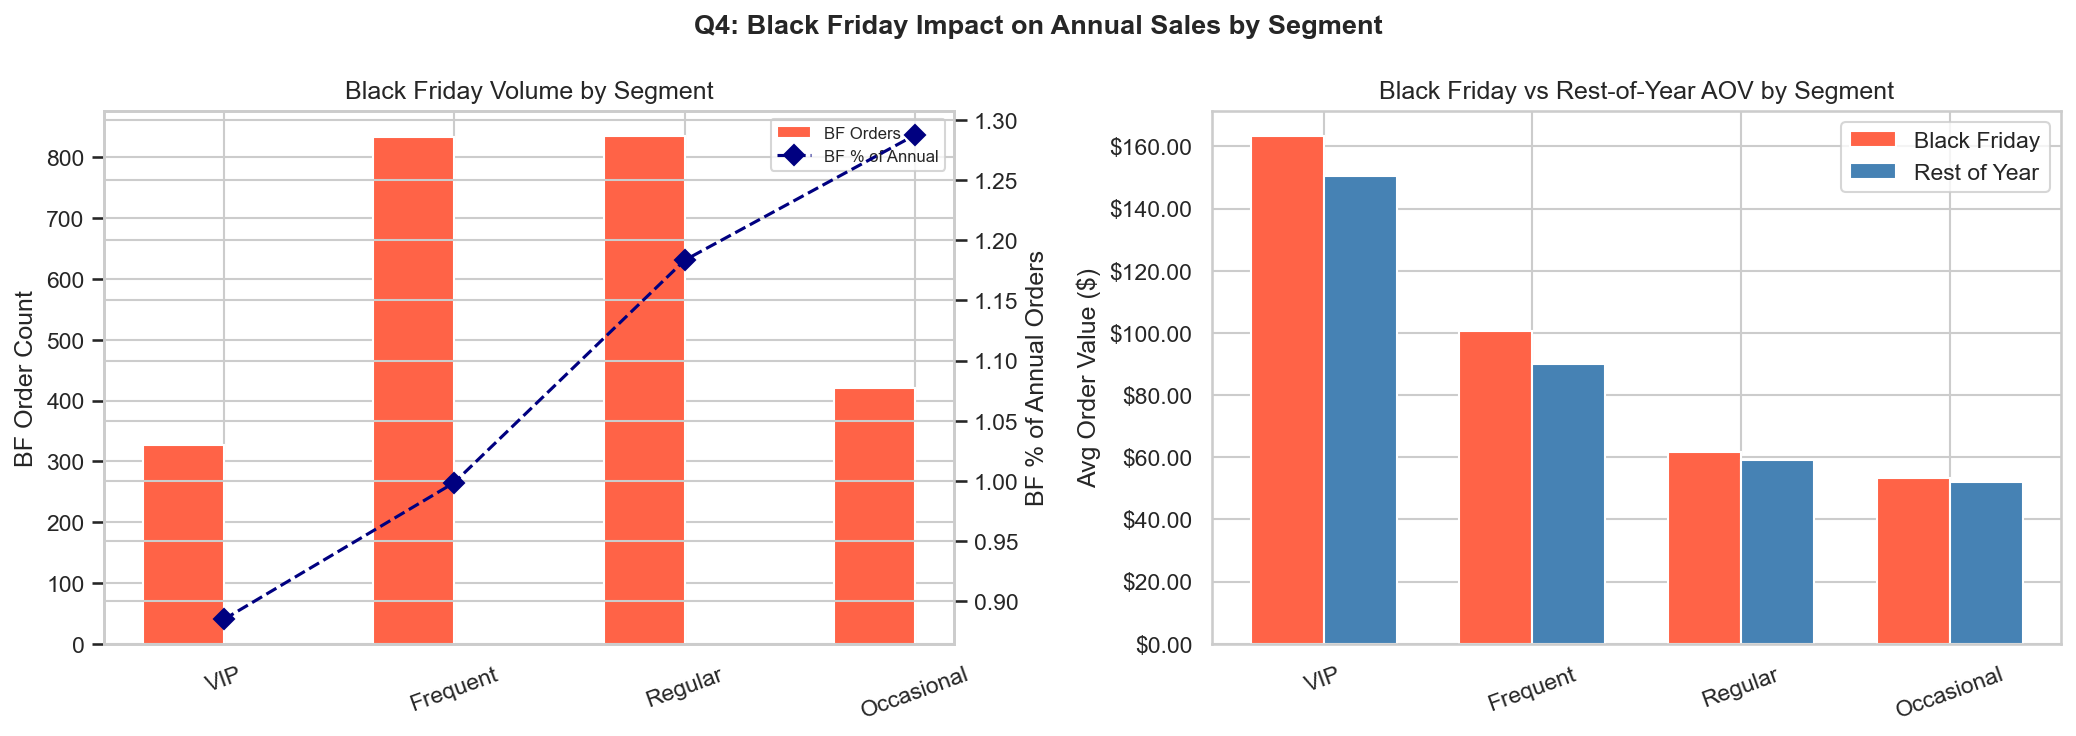

In [5]:
display(Image(FIGURES / "q4_black_friday.png"))


---
## Q5 — Best Customers: Where are they, and how do we acquire more?

**Finding:** Roughly half the buyer base (~23,700 of ~47,500) has never placed a single order.
Before optimizing spend on new acquisition, confirm whether "Dormant" is a data artifact
(default label at signup) or a genuine activation failure. Check signup_date distribution:
if Dormant buyers skew recent, the label is not a problem.

Revenue per buyer is broadly similar across regions — channel targeting matters more than
geography. VIP buyers order significantly more frequently than all other segments.

**Recommendation:** **Recommended KPIs to track:**

| KPI | Why |
|---|---|
| Buyer activation rate (% who place ≥1 order within N days) | Zero visibility in current dataset — biggest gap |
| Revenue per new buyer (by region) | Measures acquisition quality, not just volume |
| 90-day repurchase rate | Leading indicator of whether new buyers become Frequent |
| BF new buyer conversion rate | Measures acquisition effectiveness of the event |
| Catalog profit margin % | Tracks health of product rationalization effort |
| Referred buyer 90-day retention | Measures referral program ROI beyond first order |

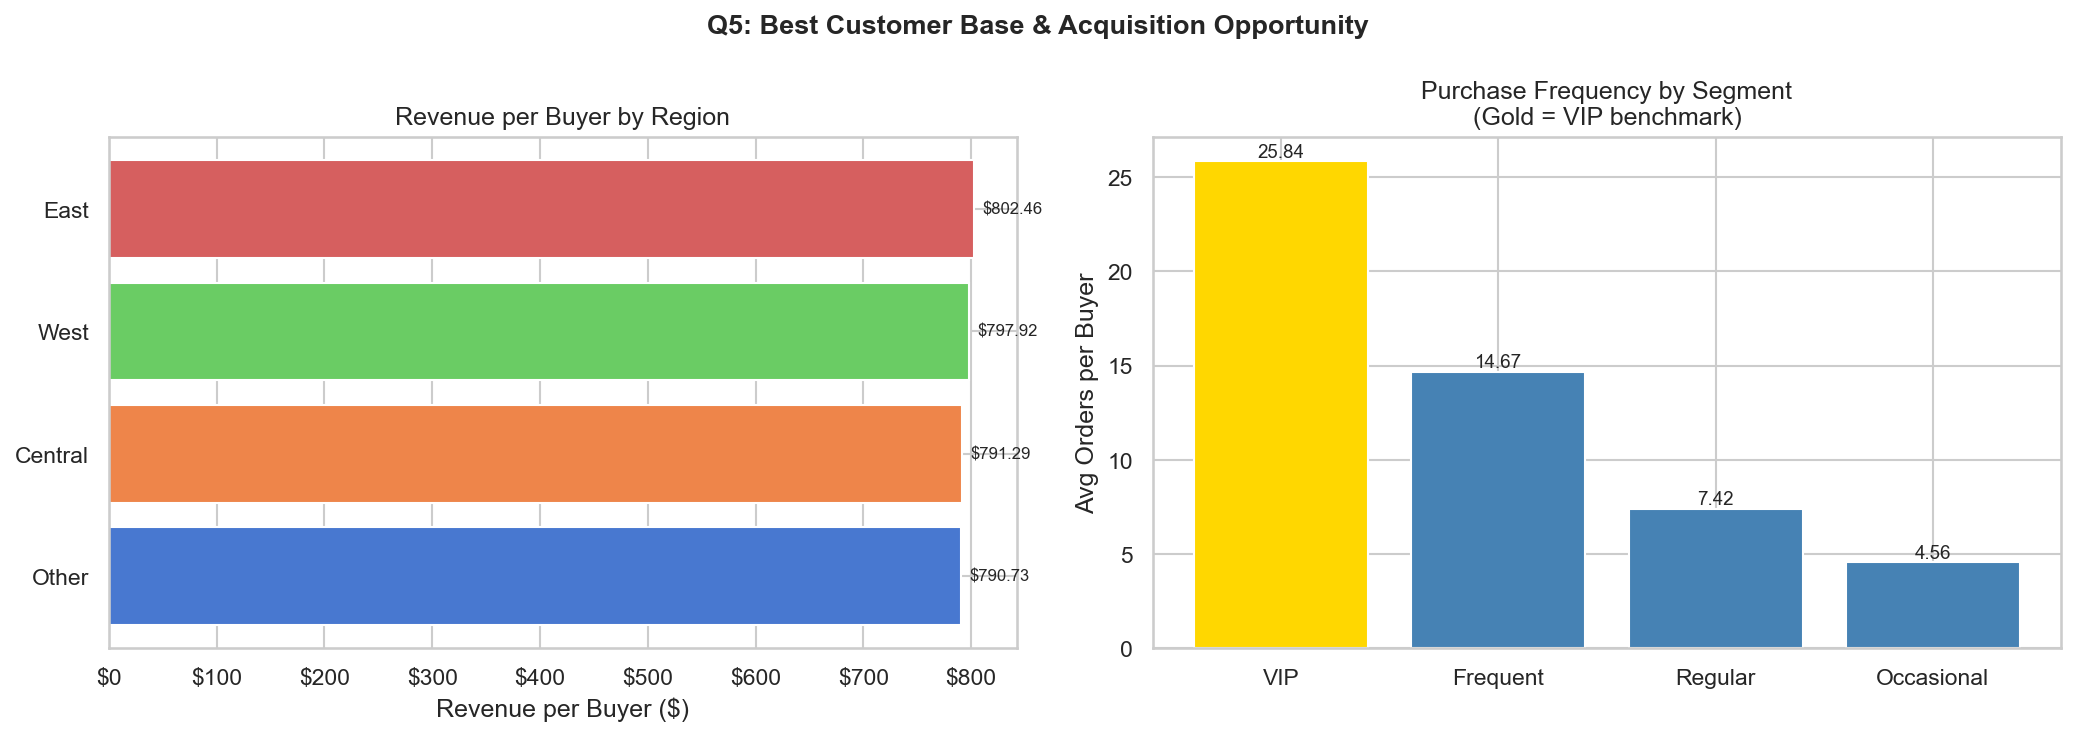

In [6]:
display(Image(FIGURES / "q5_customer_base.png"))


---
## Summary of Recommendations

| Question | Finding | Recommendation |
|---|---|---|
| Q1: 24/7 Staffing | Overnight = small % of orders | Tiered staffing — full days, reduced overnight |
| Q2: Profit by Segment | VIP/Frequent drive stable profit | Invest in retention; Dormant = 0 orders, see Q5 |
| Q3: Referral Program | No behavioral lift vs organic | Confirm terms, run 90-day cohort analysis |
| Q4: Black Friday | Volume spike, margin compressed | Acquisition event + Q1 follow-up campaign |
| Q5: Best Customers | Similar revenue across regions | Focus on channel quality + VIP frequency KPIs |

---
*Generated by `notebooks/generate_notebooks.py` — re-run to regenerate from latest pipeline output.*